# E3A. Exploring relationships between variables (with Answers)
Probability and Statistics 2023<br>
[CC BY-NC-SA](https://creativecommons.org/licenses/by-nc-sa/4.0/),
[Sakari Lukkarinen](https://peoplefinder.metropolia.fi/en/profile/8719/staff/Sakari-Lukkarinen)<br>
[Helsinki Metropolia University of Applied Sciences](https://www.metropolia.fi/en/)


We start by importing the necessary libraries and functions: 
- We use [pandas](http://pandas.pydata.org/) to [read the csv data](http://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html?highlight=read_csv#pandas.read_csv).
- [Seaborn](https://seaborn.pydata.org/index.html) provides a high-level interface for drawing attractive and informative statistical graphics. It is based on [matplotlib](https://matplotlib.org/).
- [polyfit](https://docs.scipy.org/doc/numpy/reference/generated/numpy.polyfit.html) and [polyval](https://docs.scipy.org/doc/numpy/reference/generated/numpy.polyval.html#numpy.polyval) are basic polynomial fit functions from numpy.
- [linregress](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html) calculates the linear regression model and statistics for it.
- [curve_fit](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html) can be used to fit any nonlinear function to the data.

In [6]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import linregress
from scipy.optimize import curve_fit

## Reading the data

The example data contains [body girth measurements](https://www.openintro.org/data/index.php?data=bdims) and skeletal diameter measurements, as well as age, weight, height and gender, given for 507 physically active individuals - 247 men and 260 women. These data can be used to practice data analysis. Such analyses range from simple descriptive displays to more complicated multivariate analyses such as multiple regression and discriminant analysis.

Data Source: Heinz G, Peterson LJ, Johnson RW, Kerk CJ. 2003. Exploring Relationships in Body Dimensions. Journal of Statistics Education 11(2). For more information, see https://www.openintro.org/data/ and search for `bdims.csv`.

In [2]:
# Read the example data into Python
# Remember 
file = "bdims.csv"
sep = ","
data = pd.read_csv(file, sep = sep)
data.tail()

,bia.di,bii.di,bit.di,che.de,che.di,elb.di,wri.di,kne.di,ank.di,sho.gi,...,bic.gi,for.gi,kne.gi,cal.gi,ank.gi,wri.gi,age,wgt,hgt,sex
502,38.0,30.4,32.9,17.0,27.1,12.9,10.4,19.5,14.4,108.4,...,30.3,25.4,37.7,37.9,22.4,15.4,29,71.8,176.5,0
503,35.3,28.7,30.4,17.7,25.6,12.4,9.8,17.3,13.6,99.3,...,30.1,23.6,35.6,33.3,22.4,15.2,21,55.5,164.4,0
504,34.7,24.9,24.7,17.3,24.2,12.0,10.2,18.0,13.6,91.9,...,27.4,24.0,34.4,34.1,21.2,15.5,33,48.6,160.7,0
505,38.5,29.0,32.9,15.3,25.6,12.0,9.8,18.6,13.3,107.1,...,30.6,24.9,38.4,36.6,22.0,15.5,33,66.4,174.0,0
506,35.6,29.0,29.0,20.4,26.8,13.4,10.8,18.7,13.8,100.5,...,33.2,25.5,39.6,35.9,23.0,16.4,38,67.3,163.8,0


## Correlation coefficient

Simple way to calculate the correlation between all numeric variables is to use `data.corr()`. Try that here

In [3]:
data.corr()

,bia.di,bii.di,bit.di,che.de,che.di,elb.di,wri.di,kne.di,ank.di,sho.gi,...,bic.gi,for.gi,kne.gi,cal.gi,ank.gi,wri.gi,age,wgt,hgt,sex
bia.di,1.000000,0.309036,0.486273,0.583258,0.769141,0.765821,0.722839,0.635962,0.661416,0.792596,...,0.695062,0.752642,0.507907,0.510814,0.603468,0.771598,0.086084,0.725414,0.748922,0.774948
bii.di,0.309036,1.000000,0.673457,0.356785,0.331169,0.322857,0.279236,0.437788,0.368313,0.277239,...,0.299107,0.289682,0.472469,0.407064,0.335818,0.263255,0.247878,0.495757,0.381424,0.115645
bit.di,0.486273,0.673457,1.000000,0.472556,0.524129,0.525758,0.468158,0.608302,0.495406,0.478764,...,0.480146,0.478085,0.623355,0.592980,0.539063,0.479517,0.271144,0.665725,0.485279,0.262415
che.de,0.583258,0.356785,0.472556,1.000000,0.665070,0.665238,0.608115,0.550289,0.597854,0.737612,...,0.732898,0.717549,0.563652,0.553502,0.587343,0.680241,0.315405,0.800731,0.552911,0.612886
che.di,0.769141,0.331169,0.524129,0.665070,1.000000,0.758868,0.730864,0.659065,0.668539,0.870648,...,0.792334,0.807118,0.592872,0.596909,0.635021,0.760893,0.192888,0.831465,0.626893,0.702901
elb.di,0.765821,0.322857,0.525758,0.665238,0.758868,1.000000,0.839931,0.731504,0.821098,0.819470,...,0.804784,0.858206,0.590979,0.579908,0.664162,0.845756,0.198590,0.801194,0.738113,0.772980
wri.di,0.722839,0.279236,0.468158,0.608115,0.730864,0.839931,1.000000,0.712484,0.772449,0.778399,...,0.762159,0.814709,0.581874,0.581438,0.654694,0.862553,0.207080,0.764605,0.677962,0.726855
kne.di,0.635962,0.437788,0.608302,0.550289,0.659065,0.731504,0.712484,1.000000,0.723273,0.681802,...,0.681405,0.720652,0.733818,0.686093,0.654707,0.731180,0.172336,0.766048,0.588095,0.543926
ank.di,0.661416,0.368313,0.495406,0.597854,0.668539,0.821098,0.772449,0.723273,1.000000,0.692111,...,0.686289,0.735250,0.542354,0.543616,0.677230,0.762749,0.239044,0.726468,0.686451,0.688949
sho.gi,0.792596,0.277239,0.478764,0.737612,0.870648,0.819470,0.778399,0.681802,0.692111,1.000000,...,0.895188,0.894984,0.624783,0.627054,0.679757,0.840709,0.176838,0.878834,0.665735,0.781142


In [4]:
# How to select variables
variables = ['bia.di', 'bii.di']

# How to show descriptive statistics for selected variables
data[variables].describe()

,bia.di,bii.di
count,507.000000,507.000000
mean,38.811440,27.829980
std,3.059132,2.206308
min,32.400000,18.700000
25%,36.200000,26.500000
50%,38.700000,28.000000
75%,41.150000,29.250000
max,47.400000,34.700000


If we want to calculate the correlation between two variables, we need to pick up them manually from the all variables, for example `data[['x', 'y']].corr()` would calculate the correlation between `x` and `y`.

Now, select the variables shoulder girth (`sho.gi`) and chest girth (`che.gi`) from the data and calculate the correlation between them:

In [5]:
# Practice here
var = ['sho.gi', 'che.gi'] 
data[var].corr()

,sho.gi,che.gi
sho.gi,1.000000,0.927192
che.gi,0.927192,1.000000


## Scatter-plot

Simple way to visualize the relationship between two variables is to use the scatter-plot. In pandas you can write, for example: `data.plot.scatter(x = 'x', y = 'y')`, where `x` and `y` are variables in `data`.

Using the data make a scatter plot between the shoulder (`sho.gi`) and chest (`che.gi`) girth data.

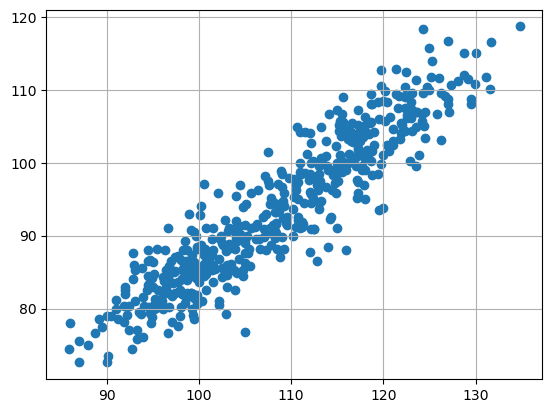

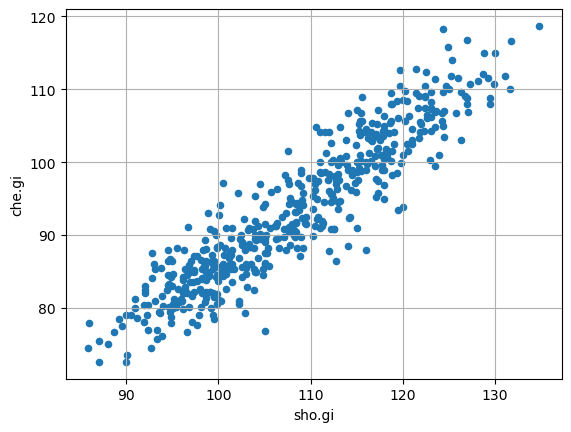

In [8]:
# Practice here
# Numpy-way to make scatter plot
x = data['sho.gi']
y = data['che.gi']
plt.scatter(x, y)
plt.grid()
plt.show()

# Pandas-ways to make scatter plot
data.plot.scatter(x = 'sho.gi', y = 'che.gi')
plt.grid()
plt.show()

## Fitting the best linear model

In this case the scatter plot shows quite strong association between these two variables. We can calculate the best linear curve fit between the variable using `numpy.polyfit` function. The basic syntax is the following `p = np.polyfit(x, y, deg)`, where `x` is the x-data, `y` is the y-data, and `deg` is the [degree (order) of the polynomial](https://en.wikipedia.org/wiki/Degree_of_a_polynomial).

Now try that for the shoulder and chest girth data used before:
- Use the shoulder girth as x-data 
- chest girth as y-data
- calculate first order polynomial fit (deg = 1)
- print polynomial coefficients `p`

In [7]:
# Practice here
x = data['sho.gi']
y = data['che.gi']
p = np.polyfit(x, y, 1)

The first parameter `p[0]` is the slope $k$ and the second parameter `p[1]` is the intercept $c$ of the linear model:

$y = k \cdot x + c$

In [8]:
p[0], p[1]

(0.8961620432600225, -3.626783563755796)

Now we can add the best fitted linear model over the scatter plot using these parameters:

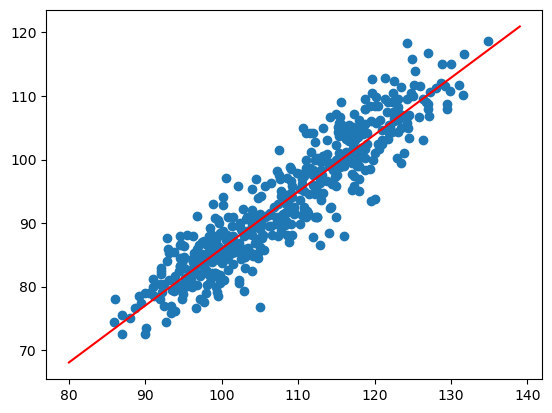

In [10]:
x1 = np.arange(80, 140)
y1 = p[0] * x1 + p[1]

# Note! you should have x assigned to shoulder girth and y to chest girth
plt.scatter(x, y)
plt.plot(x1, y1, 'r')
plt.show()

You could also directly calculate the polynomial values by using the `numpy.polyval` function. For example:

`y = np.polyval(p, x)`

calculates the same thing as:

`y = p[0] * x + p[1]`

Using the `numpy.polyfit` and `numpy.polyval` functions create a graph where you have
- a scatter plot,
- the best fitted linear model

between the shoulder and chest girth data.


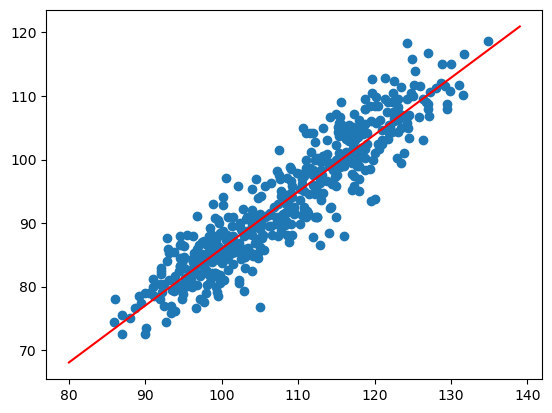

In [11]:
# practice here
y1 = np.polyval(p, x1)

plt.scatter(x, y)
plt.plot(x1, y1, color = 'red')
plt.show()

## Using linregress function

`linregress` function from `scipy.stats` library do all these calculations at once. It calculates:
- the [slope](https://en.wikipedia.org/wiki/Slope) and the [intercept](https://en.wikipedia.org/wiki/Y-intercept) of the best fitted linear model
- the correlation value (`rvalue`)
- the two-sided [p-value](https://en.wikipedia.org/wiki/P-value) (probability) value for the null hypothesis that the slope is 0, and
- the [standard error](https://en.wikipedia.org/wiki/Standard_error) of the estimated slope

The basic syntax is `r = linregress(x, y)`, where x and y are the two variables.

Calculate the output of the `linregress` for the shoulder and chest girth data and print out the results.

In [12]:
# Practice here
from scipy.stats import linregress

r = linregress(x, y)
print(r)

LinregressResult(slope=0.8961620432600229, intercept=-3.6267835637558647, rvalue=0.9271922879673856, pvalue=1.6831938314228395e-217, stderr=0.01611099126380141, intercept_stderr=1.7511096993127275)


You can pick the slope and intercept of the linear model by using the dot-notatation:

In [15]:
r.slope, r.intercept

(0.8961620432600229, -3.6267835637558647)

And you could use them to calculate and plot the best fitted linear model:

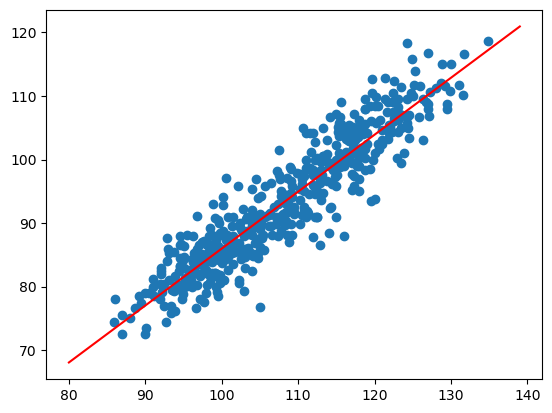

In [18]:
x2 = np.arange(80, 140)
y2 = r.slope * x2 + r.intercept
plt.scatter(x, y)
plt.plot(x2, y2, color = 'red')

Using the shoulder and chest girth data:
- Make a scatter-plot between the variables.
- Calculate the linear model using the `linregress` function.
- Calculate and plot the best fitted linear model into the same graph with the scatter-plot.

In [ ]:
# Practice here

## Using seaborn visualisations

The previous graph of combining the scatter plot and the best linear model can be done with [`regplot`](https://seaborn.pydata.org/generated/seaborn.regplot.html) function from the `seaborn` library. The standard syntax is the following: 

`sns.regplot(x = 'x', y = 'y', data = data)`, where
- `'x'` is the x-axis variable
- `'y'`is the y-axis variable, and
- `data` is the dataset.

The function have several additional parameters to finetune the graphics, for example:
- `scatter_kws = {'color': 'blue}` changes the scatter plot markers to blue color, and
- `line_kws = {'color': 'red'}` changes the linear model line to red color.

Using the `regplot` function plot the scattered data and the linear regression model between the shoulder and chest girth variables.

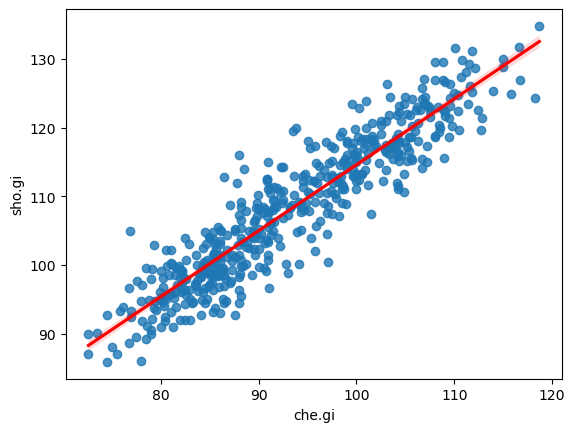

In [24]:
# Practice here
sns.regplot(x = 'che.gi', y = 'sho.gi', data = data,
           line_kws = {'color': 'red'})
plt.show()

## Using jointplot from seaborn

`jointplot` is similar to the `regplot` but it also adds histograms and density plots of the variables on the axis. The basic syntax is the following:

`sns.jointplot(data = data, x = 'x', y = 'y', kind = 'reg')`, where
- data is the dataset
- x is the first variable plot on x-axis
- y is the second variable plot on y-axis
- kind defines the kind of plot to draw. In this case it adds histograms and regression and density fits to the graph.

Using the `jointplot` function plot the scattered data and the linear regression model between the shoulder and chest girth variables. Add also the histograms and regression and density fits to the graph.

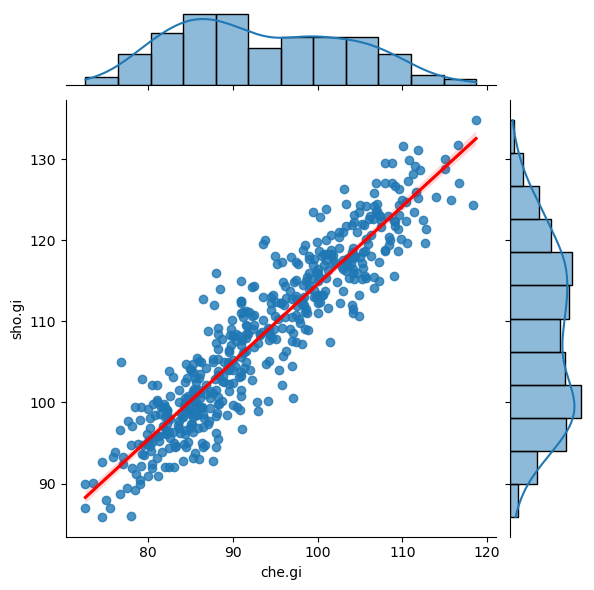

In [26]:
# Practice here
sns.jointplot(x = 'che.gi', y = 'sho.gi', data = data, kind = 'reg',
             line_kws = {'color': 'red'})
plt.show()

## Using residplot from seaborn

`residplot` calculates and plots the residuals (difference between the data points and the linear model) between the model and the data. 

For example `sns.residplot(data = data, x = 'x', y = 'y')` finds out the best fitted linear model $y_{model} = kx + c$ and then calculates the residuals $res = y_{data} - y_{model}$ and plots that in the y-axis.

Using the `residplot` function plot the residuals of the linear model between the shoulder and chest girth data.

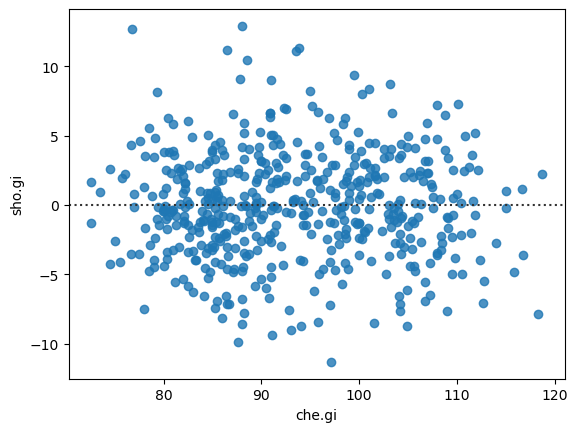

In [27]:
# Practice here
sns.residplot(data = data, x = 'che.gi', y = 'sho.gi')
plt.show()

As can be seen from the graph, the residuals are evenly distributed above and below the center-line which confirms that the linear model works fine in this case.

## More statistical comparison tools 

Below are some more statistical comparisons done with seaborn and pandas.

Compare the chest diameters between `sex`. Show the results using boxplot.

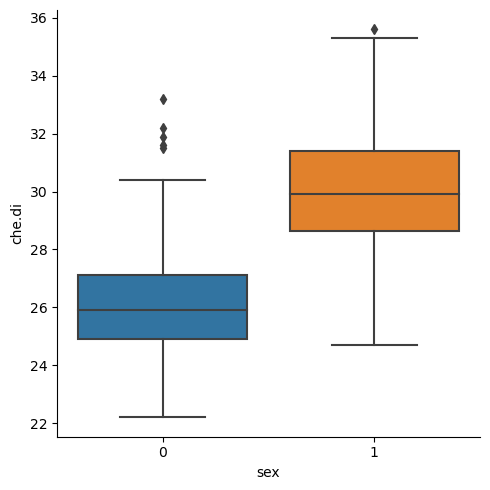

In [28]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

sns.catplot(data=data, x="sex", y="che.di", kind="box")
plt.show()

Compare the chest diameter between `sex`. Use default jitter-plot.

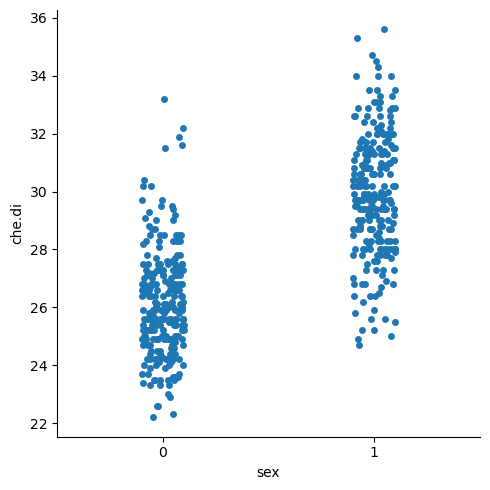

In [29]:
sns.catplot(data=data, x="sex", y="che.di")
plt.show()

### Linear regression plot for two groups
Generate linear regression plot "che.gi" vs. sho.gi". Uses "sex" to group the data. As a results, two linear regression lines (one for each group) is plotted

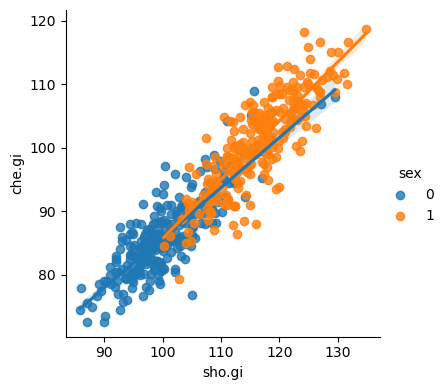

In [30]:
g = sns.lmplot(
    data=data,
    x="sho.gi", y="che.gi", hue="sex",
    height=4)

### Pairplot between several variables

The following code creates a pairplot between several variables. It shows kernel plots (continuous histograms) for each variable and scatter-plots between variable pairs. Data is grouped by "sex" using the hue parameter.


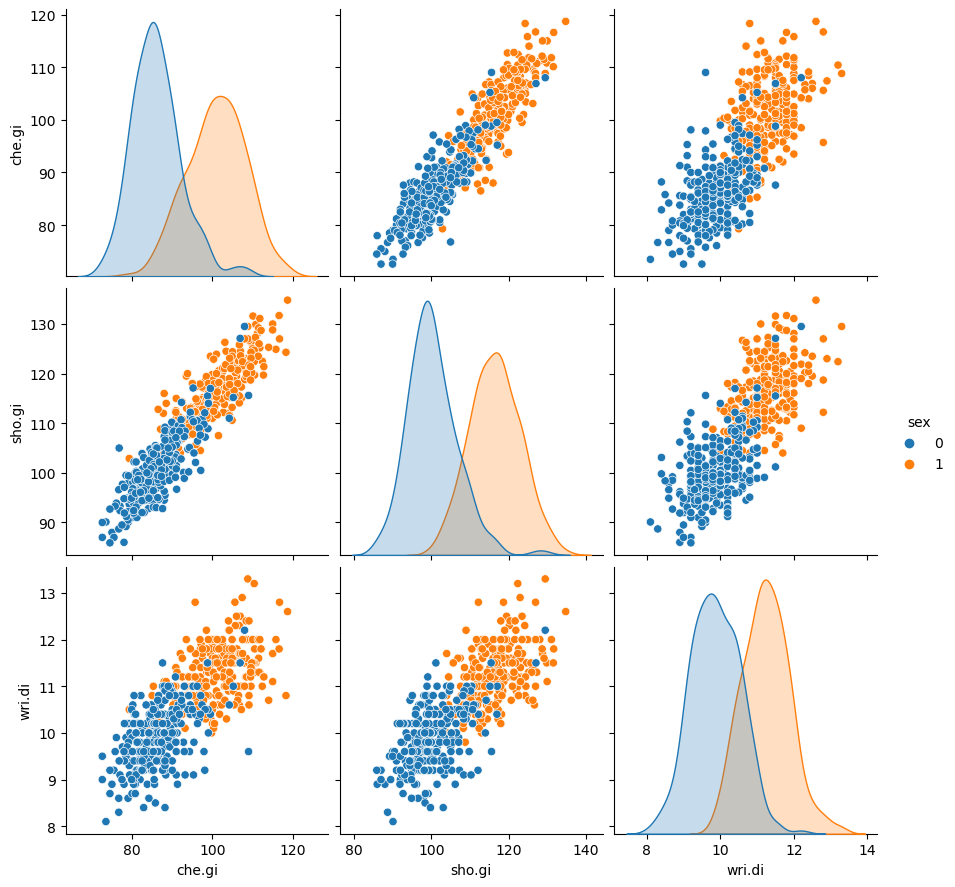

In [31]:
sns.pairplot(data = data[['che.gi', 'sho.gi', 'wri.di','sex']], 
             hue = 'sex', 
             height = 3);

# Crosstabulated table

This code creates a crosstabulated table where data is splitted into two groups based on sex (columns) and shoulder girth (rows). Crosstab counts all values belonging to each category. `margins = True` adds subtotals for all rows and columns.

In [32]:
table = pd.crosstab([data['sho.gi'].between(0, 110)], data['sex'],
           margins = True)
print(table)

sex       0    1  All
sho.gi               
False    19  207  226
True    241   40  281
All     260  247  507


More info:
- [Visualizing categorical data](https://seaborn.pydata.org/tutorial/categorical.html#categorical-tutorial)
- [pandas.crosstab](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.crosstab.html)
- [Pandas crosstab explained](https://pbpython.com/pandas-crosstab.html)